In [1]:
# 导入需要的库
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 设置图表在 Notebook 中直接显示
%matplotlib inline 

# 指定文件路径（确保 housing.csv 和你的代码在同一个文件夹！）
data_file = Path('housing.csv')

# 检查文件是否存在
if not data_file.exists():
    print("❌ 错误：找不到 housing.csv 文件，请确保它和代码在同一个文件夹！")
else:
    # 读取数据
    df = pd.read_csv(data_file)
    print("✅ 数据读取成功！")
    print(f"数据总行数: {len(df)}")
    print(f"数据总列数: {len(df.columns)}")
    print("\n前 5 行数据预览：")
    display(df.head())

✅ 数据读取成功！
数据总行数: 20640
数据总列数: 10

前 5 行数据预览：


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [2]:
# 检查每一列有多少缺失值
print("清理前，各列的缺失值数量：")
print(df.isnull().sum())

# 删除包含缺失值的行（最安全简单的清理方式）
df_clean = df.dropna()

print("\n✅ 清理完成！")
print(f"清理后剩余数据行数: {len(df_clean)}")

清理前，各列的缺失值数量：
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

✅ 清理完成！
清理后剩余数据行数: 20433


✅ 第一张图已生成并保存为: plot1_geo_scatter.png


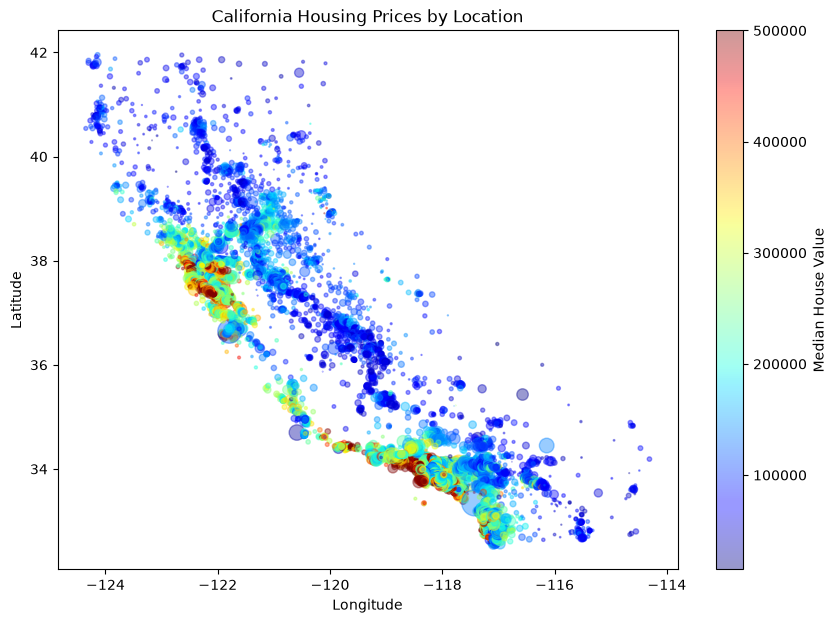

In [3]:
# 设置图表大小
plt.figure(figsize=(10, 7))

# 绘制散点图：X轴是经度，Y轴是纬度，颜色深浅代表房价，圆圈大小代表人口
scatter = plt.scatter(df_clean['longitude'], df_clean['latitude'], 
                      alpha=0.4, 
                      s=df_clean['population']/100, # 圆圈大小根据人口缩放
                      c=df_clean['median_house_value'], # 颜色根据房价
                      cmap='jet') # 颜色主题

# 添加颜色条
plt.colorbar(scatter, label='Median House Value')

# 添加标题和坐标轴标签
plt.title('California Housing Prices by Location')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# 保存图片到本地（重要！之后要传到 GitHub）
plt.savefig('plot1_geo_scatter.png', dpi=300, bbox_inches='tight')
print("✅ 第一张图已生成并保存为: plot1_geo_scatter.png")

# 在 Notebook 中显示图表
plt.show()

✅ 第二张图已生成并保存为: plot2_income_value.png


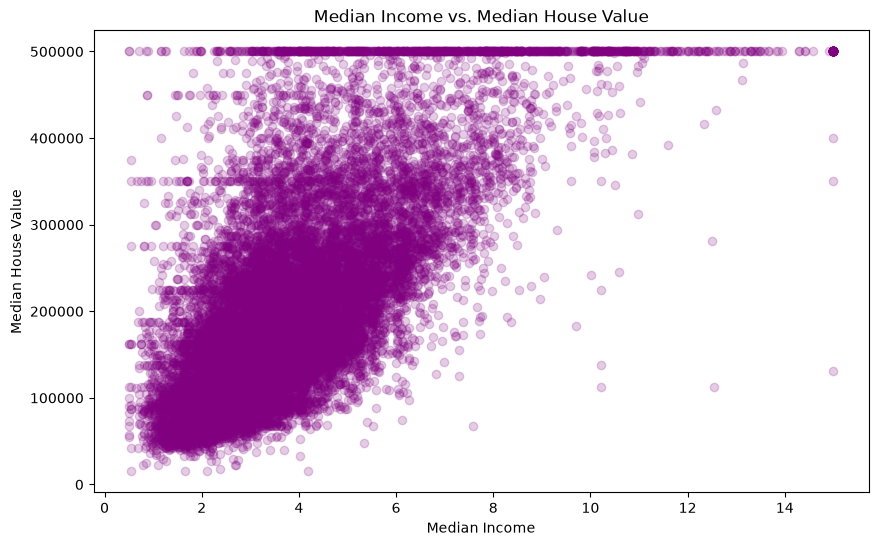

✅ requirements.txt 文件已生成！


In [4]:
# 设置图表大小
plt.figure(figsize=(10, 6))

# 绘制散点图：X轴是收入，Y轴是房价
plt.scatter(df_clean['median_income'], df_clean['median_house_value'], 
            alpha=0.2, color='purple')

# 添加标题和坐标轴标签
plt.title('Median Income vs. Median House Value')
plt.xlabel('Median Income')
plt.ylabel('Median House Value')

# 保存图片到本地（重要！）
plt.savefig('plot2_income_value.png', dpi=300, bbox_inches='tight')
print("✅ 第二张图已生成并保存为: plot2_income_value.png")

# 显示图表
plt.show()

# ==========================================
# 自动生成 requirements.txt 文件
# ==========================================
with open('requirements.txt', 'w') as f:
    f.write("pandas\nmatplotlib\n")
    
print("✅ requirements.txt 文件已生成！")